In [1]:
from pathlib import Path
import pandas as pd

In [2]:
file_path = Path("../data/train.csv")

file_size = file_path.stat().st_size
size_mb = file_size / (1024 ** 2)
# size_gb = file_size / (1024 ** 3)
print(f"Size bytes: {file_size}")
print(f"Size mb: {size_mb:.2f} MB")

Size bytes: 38057952
Size mb: 36.29 MB


In [3]:
train_df = pd.read_csv("../data/train.csv")
train_df.head()

C:\Users\ecole\AppData\Local\Temp\ipykernel_49560\3743472639.py:1: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv("../data/train.csv")


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [7]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 69.8+ MB


## Data Cleaning

In [4]:
# correct Date column
train_df["Date"] = pd.to_datetime(train_df['Date'], errors='raise', format="%Y-%m-%d")
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[us](1), int64(7), object(1)
memory usage: 69.8+ MB


In [9]:
train_df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [ ]:
# clean StateHoliday column
train_df['StateHoliday'].unique()

array(['0', 'a', 'b', 'c', 0], dtype=object)

In [5]:
train_df['StateHoliday'] = train_df['StateHoliday'].replace(0, '0').astype('str')
train_df['StateHoliday'].unique()

<StringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str

In [6]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  str           
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[us](1), int64(7), str(1)
memory usage: 69.8 MB


## Inspection

In [20]:
train_df['Open'].value_counts()

Open
1    844392
0    172817
Name: count, dtype: int64

172817 records are present in data that are closed
drop them store is closed
first check if any sale is recorded when store is closed?


In [6]:
closed_stores = train_df.loc[train_df['Open']==0]

closed_stores['Sales'].gt(0).sum()

np.int64(0)

In [7]:
# nice, so drop Open=0
train_df = train_df.loc[train_df['Open']==1]
train_df['Open'].unique()

array([1])

In [8]:
# - How many observations does each store have?
store_counts = train_df['Store'].value_counts().sort_index()
store_counts

Store
1       781
2       784
3       779
4       784
5       779
       ... 
1111    779
1112    779
1113    784
1114    784
1115    781
Name: count, Length: 1115, dtype: int64

In [9]:
store_counts.describe()

count    1115.000000
mean      757.302242
std        63.861126
min       592.000000
25%       776.000000
50%       779.000000
75%       782.000000
max       942.000000
Name: count, dtype: float64

Statistic	Value	Meaning
Count	1,115	Number of stores
Mean	757.3	Average open-day observations per store
Std	63.86	How much observation counts vary
Min	592	Store with the fewest observations
25%	776	25% of stores have at most 776 observations
50%	779	Median store has 779 observations
75%	782	75% of stores have at most 782 observations
Max	942	Store with the most observations

In [17]:
store_counts.sort_values().head()

Store
644    592
348    597
744    605
100    606
909    607
Name: count, dtype: int64

In [18]:
print((store_counts < 700).sum())
print((store_counts < 750).sum())
print((store_counts < 776).sum())

181
186
252


- How many stores have fewer than 700 observations?
181

- How many have fewer than 750?
186

- How many fall below the first quartile?
252

### Global model vs individual models per store

- One of the experiments I want to conduct is on model architecture strategy: Should we train one global model or individual models per store?

- After filtering out records where stores were closed (`Open == 0`), I checked the number of available open-day observations per store.

- We have 1,115 stores. Most have around 779 observations, but some have considerably fewer.

- I started wondering whether the amount of available data per store would affect how well individual models generalize. Haven't tested this yet, just a thought.

- Another approach is to include `Store` as a feature and let the global model learn store-specific patterns alongside shared patterns.

- I could experiment with these approaches later.

**My failed attempt at EDA**

- At first, I tried visualizing the correlation between store sales using a heatmap. Wrong move. Ha! I couldn't understand anything.

- I forgot we have a freaking 1,115 unique stores, each with their own sales observations. What exactly was I expecting to see in that heatmap?

- I don't even think I need to do extensive EDA on the relationships between stores before conducting this experiment. The modelling experiment itself will help me investigate the differences.

- I realized that sometimes I don't need to prove beforehand that an approach (individual models, for example) is better or worse. That's what the experiment is for.

- GPT was like, "That's what the experiment is for."

- EXACTLY.

Why do I like stressing myself? Why? Even I don't understand.

Good lesson: learn to prioritize and know what's actually worth spending time investigating.

In [22]:
train_df.to_csv("../data/clean/train.csv", index=False)

## Stores Available history inspection

<!-- - do in a .py file? not ipynb -->
<!-- then use ipynb to read and inspeact -->

1. How many observations each store has.
2. How far back each store's historical records go.


In [10]:
store_history = train_df.groupby("Store").agg(
    first_date=('Date', 'min'),
    last_date=('Date', 'max'),
    observations=('Date', 'count')
)
store_history.head()

,first_date,last_date,observations
Store,,,
1,2013-01-02,2015-07-31,781
2,2013-01-02,2015-07-31,784
3,2013-01-02,2015-07-31,779
4,2013-01-02,2015-07-31,784
5,2013-01-02,2015-07-31,779



| Group                 | First recorded date |
| --------------------- | ------------------- |
| Long-history stores   | 2013                |
| Medium-history stores | 2014                |
| Short-history stores  | 2015                |


In [11]:
# 2. Group history to group
import numpy as np

conditions = [
    store_history['first_date'] < '2014-01-01', # less than 2014
    store_history['first_date'].between('2014-01-01', '2014-12-31'), # within 2014
    store_history['first_date'] >= '2015-01-01' # greater than 2015
]

choices = ['Long', 'Medium', 'Short']

store_history['history_group'] = np.select(conditions, choices, default='Other')
store_history.head()

,first_date,last_date,observations,history_group
Store,,,,
1,2013-01-02,2015-07-31,781,Long
2,2013-01-02,2015-07-31,784,Long
3,2013-01-02,2015-07-31,779,Long
4,2013-01-02,2015-07-31,784,Long
5,2013-01-02,2015-07-31,779,Long


In [ ]:
store_history['history_group'].value_counts()

history_group
Long    1115
Name: count, dtype: int64

In [13]:
history_summary = store_history.groupby("history_group").agg(
    stores=("observations", "size"),
    min_observations=("observations", "min"),
    median_observations=("observations", "median"),
    max_observations=("observations", "max"),
)

history_summary


,stores,min_observations,median_observations,max_observations
history_group,,,,
Long,1115,592,779.0,942


In [16]:
store_history["last_date"].value_counts(normalize=True).sort_index()


last_date
2015-07-10    0.000897
2015-07-15    0.000897
2015-07-31    0.998206
Name: proportion, dtype: float64

wow okay, so the first recorded history for all stores is dated back 2013
all stores has Long history

the latest recorded history for all Stores is 2015,
with 99.8% recorded 2015-07-31
and 1 record each for 2015-07-10, and 2015-07-15

with this
Initialy I wanted to investigate whether forecasting performance changes as available history decreases.
But now I see the data avialble doesn't support this.
So i would simulate stores with short history to run the experiment.

## Investigate relationships between stores

- because I want to know before 

In [12]:
# - Correlation between store sales.
# do sales at different store  move together?
store_sales = train_df.pivot(columns="Store", values="Sales", index="Date")
sales_corr = store_sales.corr()

Text(0.5, 1.0, 'Correlation Between Store Sales')

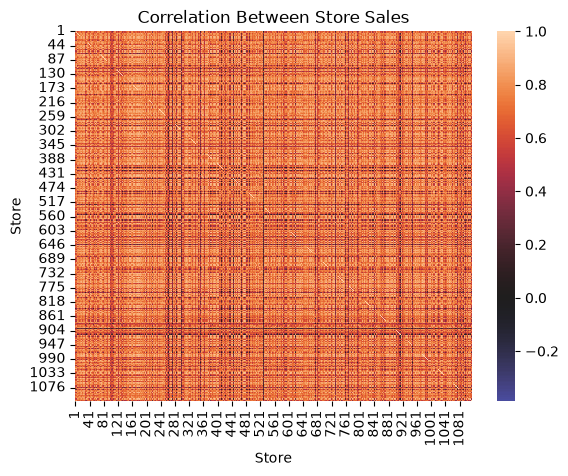

In [14]:
import seaborn as sns

sns.heatmap(data=sales_corr, center=0)
plt.title("Correlation Between Store Sales")


In [17]:
train_df['Date'].dt.year.unique()

array([2015, 2014, 2013], dtype=int32)